In [1]:
#libaraies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error ,mean_absolute_error

In [2]:
df = pd.read_csv("/content/used_car_price_dataset_extended.csv")

In [3]:
print(df.head())

   make_year  mileage_kmpl  engine_cc fuel_type  owner_count  price_usd  \
0       2001          8.17       4000    Petrol            4    8587.64   
1       2014         17.59       1500    Petrol            4    5943.50   
2       2023         18.09       2500    Diesel            5    9273.58   
3       2009         11.28        800    Petrol            1    6836.24   
4       2005         12.23       1000    Petrol            2    4625.79   

       brand transmission  color service_history  accidents_reported  \
0  Chevrolet       Manual  White             NaN                   0   
1      Honda       Manual  Black             NaN                   0   
2        BMW    Automatic  Black            Full                   1   
3    Hyundai       Manual   Blue            Full                   0   
4     Nissan    Automatic    Red            Full                   0   

  insurance_valid  
0              No  
1             Yes  
2             Yes  
3             Yes  
4             Ye

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           10000 non-null  int64  
 1   mileage_kmpl        10000 non-null  float64
 2   engine_cc           10000 non-null  int64  
 3   fuel_type           10000 non-null  object 
 4   owner_count         10000 non-null  int64  
 5   price_usd           10000 non-null  float64
 6   brand               10000 non-null  object 
 7   transmission        10000 non-null  object 
 8   color               10000 non-null  object 
 9   service_history     7962 non-null   object 
 10  accidents_reported  10000 non-null  int64  
 11  insurance_valid     10000 non-null  object 
dtypes: float64(2), int64(4), object(6)
memory usage: 937.6+ KB
None


In [5]:
print(df.isnull().sum())

make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64


In [6]:
df_clean = df.dropna()

In [7]:
print(df_clean.isnull().sum())

make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
price_usd             0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
dtype: int64


Text(0, 0.5, 'Count')

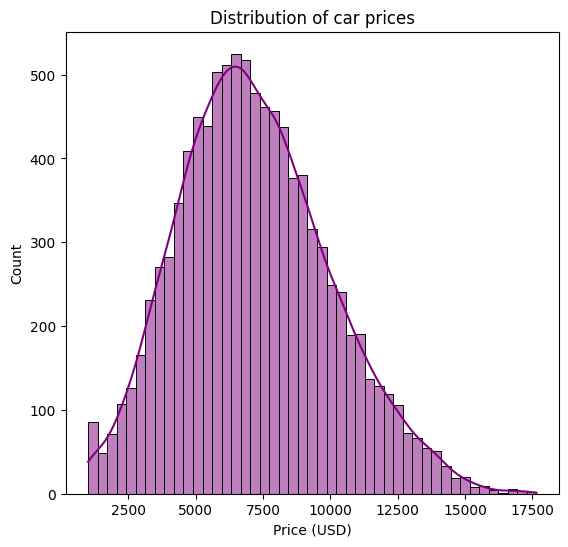

In [10]:
plt.figure(figsize=(14, 6))
plt.subplot(1,2,1)
sns.histplot(df["price_usd"],kde=True ,color="Purple")
plt.title("Distribution of car prices")
plt.xlabel("Price (USD)")
plt.ylabel("Count")

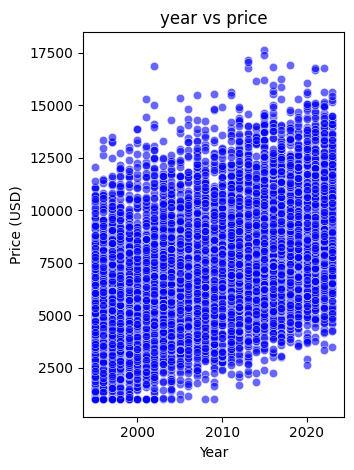

In [12]:
plt.subplot(1,2,2)
sns.scatterplot(x=df["make_year"], y=df["price_usd"], color="blue", alpha=0.6)
plt.title("year vs price")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

In [14]:

features = ["make_year", "mileage_kmpl", "engine_cc", "owner_count", "accidents_reported"]
X = df_clean[features]
y = df_clean["price_usd"]

X_train ,X_test ,y_train , y_test = train_test_split(X,y,test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train , y_train)

y_pred = model.predict(X_test)
print("MSE Error:", mean_squared_error(y_test , y_pred))

MSE Error: 1816673.7540730536


RMSE: 1347.8404037841622
MAE: 1007.5985120118853
MSE: 1816673.7540730536


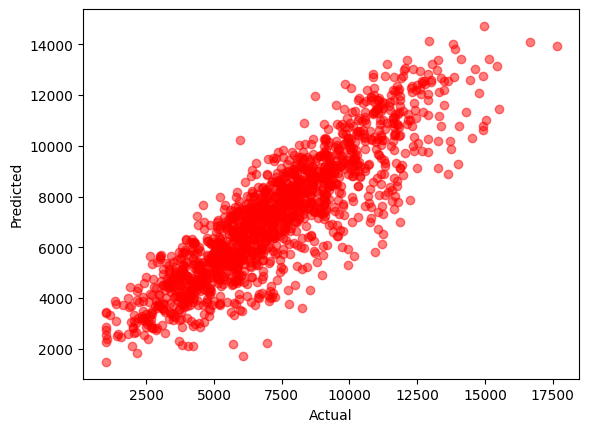

In [17]:
print("RMSE:", np.sqrt(mean_squared_error(y_test,y_pred)))
print("MAE:",mean_absolute_error(y_test , y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))

plt.scatter(y_test,y_pred, color="red",alpha=0.5)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()